# EricaNext SMILE-2+ クイックスタート

このノートブックは、SMILE-2+ の生データ(TPC の μTPC 波形 + HA シンチレータ)から
コンプトン再構成イベント(`Eg`, `Ke`, `cos_phi` など)を得るまでを、
[EricaNext](https://github.com/SMILE-tool-box/EricaNext)(ANLNext フレームワーク上の解析パイプライン)を使って一通りたどるチュートリアルです。

Fermipy / cosipy のクイックスタートと同じ構成にしています:

1. 環境セットアップ
2. 入力データの確認
3. 解析チェーンの構築・実行(スクリプトとして)
4. 出力 ROOT ファイルの中身を可視化

> **注意**: ここで使う `SMILEsoft/src/data/Per03_ETCC` はテスト用の小さなサンプルデータです。
> `TPC_Calibration` には実際の較正ファイル `SMILEsoft/src/data/Calibration20190130.dat` を使っていますが、
> これは Per03_ETCC とは別の較正キャンペーンのものなので、エネルギースケールはあくまで参考値です。
> 本番解析では、そのデータセットに対応した較正ファイルを使ってください。

## 1. 環境セットアップ

EricaNext は C++ で書かれたモジュール群を ANLNext フレームワーク上で SWIG 経由の
Python 拡張 `EricaPy` として使います。ビルド済みの `install/lib/python` を `sys.path` に追加します。

In [1]:
import sys, os

# EricaNext_try のビルド済みインストール先(このノートブックが notebooks/ に置かれている前提)
ERICANEXT_INSTALL = os.path.abspath(os.path.join(os.path.dirname(os.path.abspath("__file__")), "..", "install"))

# 注意: /usr/local/lib/python には別ビルドの EricaPy が入っていることがあるため、
# 必ず EricaNext_try の install を先に(index 0 に)通す順序で追加する
sys.path.insert(0, "/usr/local/lib/python")  # ANLNext 本体の python バインディング
sys.path.insert(0, os.path.join(ERICANEXT_INSTALL, "lib", "python"))  # EricaNext_try 自身のビルド(優先)

import ROOT
ROOT.PyConfig.IgnoreCommandLineOptions = True
ROOT.gROOT.SetBatch(True)

import numpy as np
import matplotlib.pyplot as plt

print("environment OK")

environment OK


## 2. 入力データ

SMILE-2+ の生データは、TPC(アノード/カソード μTPC 波形)とシンチレータ(HA)がそれぞれ
別ファイル群として `data_dir` の下に置かれています(例: `uTPC_anode1_00000.raw`, `HA01_00000.raw`, ...)。
`ReadData` モジュールがこれらをイベント ID で同期しながら読み込みます。

In [2]:
DATA_DIR = "/home/onoda/ANLNext/SMILEsoft/src/data/Per03_ETCC"
CALIBRATION_FILE = "/home/onoda/ANLNext/SMILEsoft/src/data/Calibration20190130.dat"
HA_PARAMETER_DIR = "/home/onoda/ANLNext/SMILEsoft/src/data/HA_Parameters_201901"
OUTPUT_ROOT = os.path.abspath("tutorial_output.root")
N_EVENTS = 300  # -1 にすると全イベント

sorted(os.listdir(DATA_DIR))[:10]

['.@__thumb',
 'HA01_00000.raw',
 'HA01_00001.raw',
 'HA01_00002.raw',
 'HA01_00003.raw',
 'HA01_00004.raw',
 'HA01_00005.raw',
 'HA01_00006.raw',
 'HA02_00000.raw',
 'HA02_00001.raw']

## 3. 解析チェーンの構築・実行

EricaNext のパイプラインは大きく 4 つの層に分かれています(詳細は Notion の設計ドキュメント参照):

| 層 | モジュール | 役割 |
|---|---|---|
| 0. 入力 | `SaveFile`, `ReadData` | 出力 ROOT を開く / raw ファイルを読んでイベント同期 |
| 1. 検出器ごとの較正 | `CalcFADC` → `TPC_Calibration`, `TOT_Skewness`, `HA_CenterGravity` → `HA_Calc` | TPC の電荷・飛跡・エネルギー、HA(シンチ)の位置・エネルギー |
| 2. イベント再構成 | `Reconstruct` | TPC の反跳電子情報とシンチのヒットを合わせてコンプトン再構成 |
| 3. 出力 | (Reconstruct が書く `single_hit` TTree) | 下流のイメージング・偏光解析への入力 |

`AnalysisChain` に `chain()` でモジュールを追加し、`with_parameters()` でパラメータを渡します。

> **実装メモ**: `CalcFADC` は波形積分を `std::thread` で並列に行い、その中から直接 ROOT の
> ヒストグラムに `Fill` します。この処理を Jupyter の ipykernel プロセスの中でそのまま動かすと、
> ipykernel 自身が持つスレッド(ハートビート等)と衝突してカーネルごと落ちることがあります
> (プレーンな python スクリプトとして実行する分には問題ありません)。
> そのため、ここではチェーンの構築・実行を **別プロセスのスクリプトとして書き出して実行**し、
> ノートブック側(このカーネル)は結果の ROOT ファイルを読んで可視化するだけにしています。

In [3]:
chain_script = f'''
import sys
sys.path.insert(0, "/usr/local/lib/python")
sys.path.insert(0, {os.path.join(ERICANEXT_INSTALL, "lib", "python")!r})

import anlnext
import EricaPy as erica

a = anlnext.AnalysisChain()

# --- 層0: 出力ファイルを開き、raw データを読む ---
a.chain(erica.SaveFile)
a.with_parameters({{"filename": {OUTPUT_ROOT!r}}})

a.chain(erica.ReadData)
a.with_parameters({{
    "data_dir": {DATA_DIR!r},
    "reverse_TPC": False,
    "TPC_Only": False,   # False にすると HA(シンチ)も読む
}})

# --- 層1a: TPC の電荷 -> エネルギー、飛跡 -> 反跳電子の点・方向・skewness ---
a.chain(erica.CalcFADC)
a.with_parameters({{
    "base_window": 30.0,
    "threshold": 20.0,
}})

a.chain(erica.TPC_Calibration)
a.with_parameters({{
    "NoCalData": False,
    "ParameterFile": {CALIBRATION_FILE!r},
}})

a.chain(erica.TOT_Skewness)
a.with_parameters({{
    "pitch_x_mm_per_strip": 0.4,
    "pitch_y_mm_per_strip": 0.4,
    "pitch_z_mm_per_clock": 0.5,
    "clock_offset": 90.0,
    "flag_pixel_cut": False,
    "flag_save_cloud": True,
}})

# --- 層1b: HA(シンチ)の重心・位置・エネルギー較正(SMILE-2+ の HA80256 専用) ---
a.chain(erica.HA_CenterGravity)
a.with_parameters({{
    "threshold": 10,
    "overflow": 4000,
}})

a.chain(erica.HA_Calc)
a.with_parameters({{
    "parameter_dir": {HA_PARAMETER_DIR!r},
    "Cal_Mode": True,
}})

# --- 層2: TPC + HA を合わせたコンプトン再構成 ---
a.chain(erica.Reconstruct)

a.run({N_EVENTS})
'''

with open("run_chain.py", "w") as fh:
    fh.write(chain_script)

print(chain_script)


import sys
sys.path.insert(0, "/usr/local/lib/python")
sys.path.insert(0, '/home/onoda/ANLNext/EricaNext_try/install/lib/python')

import anlnext
import EricaPy as erica

a = anlnext.AnalysisChain()

# --- 層0: 出力ファイルを開き、raw データを読む ---
a.chain(erica.SaveFile)
a.with_parameters({"filename": '/home/onoda/ANLNext/EricaNext_try/notebooks/tutorial_output.root'})

a.chain(erica.ReadData)
a.with_parameters({
    "data_dir": '/home/onoda/ANLNext/SMILEsoft/src/data/Per03_ETCC',
    "reverse_TPC": False,
    "TPC_Only": False,   # False にすると HA(シンチ)も読む
})

# --- 層1a: TPC の電荷 -> エネルギー、飛跡 -> 反跳電子の点・方向・skewness ---
a.chain(erica.CalcFADC)
a.with_parameters({
    "base_window": 30.0,
    "threshold": 20.0,
})

a.chain(erica.TPC_Calibration)
a.with_parameters({
    "NoCalData": False,
    "ParameterFile": '/home/onoda/ANLNext/SMILEsoft/src/data/Calibration20190130.dat',
})

a.chain(erica.TOT_Skewness)
a.with_parameters({
    "pitch_x_mm_per_strip": 0.4,
    "pitch_y_mm_per_strip": 0.4,
    "pitch_z_m

In [4]:
import subprocess

result = subprocess.run(
    [sys.executable, "run_chain.py"],
    cwd=os.path.dirname(os.path.abspath("__file__")) or ".",
    capture_output=True, text=True,
)
print(result.stdout[-3000:])
if result.returncode != 0:
    print(result.stderr[-3000:])
result.check_returncode()
print()
print("chain finished OK ->", OUTPUT_ROOT)

 0
    [   5]  HA_CenterGravity  version  1.0          
           297  |  OK:        243 | Skip:         54 | Error:          0
    [   6]  HA_Calc  version  1.0                   
           243  |  OK:        243 | Skip:          0 | Error:          0
    [   7]  Reconstruct  version  1.0               
           243  |  OK:        243 | Skip:          0 | Error:          0
               Get: 243


        **************************************
        ****  Result of Event Selections  ****
        **************************************

  Number of EVS : 18
------------------------------------------------------------------------------
                 key                        |     counts     |   completed    
------------------------------------------------------------------------------
Anode_Data                                                300              243
Cathode_Data                                              300              243
ClearPulse80256                    

## 4. 出力の確認

出力 ROOT ファイルには、モジュールごとのディレクトリが作られています。

In [5]:
f = ROOT.TFile.Open(OUTPUT_ROOT)
for key in f.GetListOfKeys():
    print(key.GetName())

ReadData
CalcFADC
TPC_Calibration
TOT_Skewness
HA_CGravity
HA_Calc
Reconstruct


### 4a. TPC トラック再構成(`TOT_Skewness`)

`TOT_Skewness` は、TPC の μTPC 飛跡から反跳電子の散乱点 `Pe`・方向 `Ve`・飛程 `Len`・
skewness(飛跡の非対称性、電子の進行方向を決めるのに使う)を再構成します。

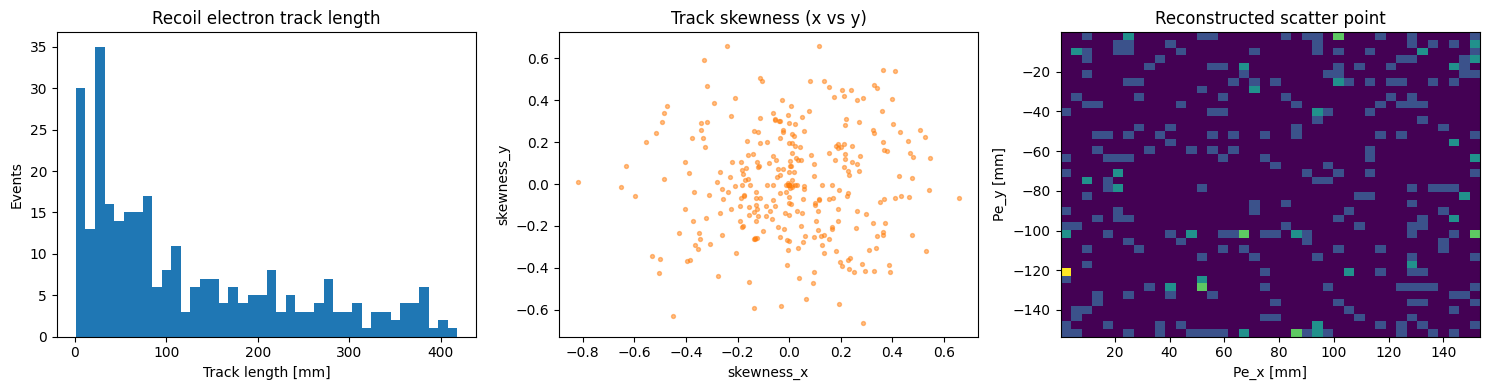

In [6]:
tree = f.Get("TOT_Skewness/tot_skewness")

lens, skx, sky, pex, pey = [], [], [], [], []
for i in range(tree.GetEntries()):
    tree.GetEntry(i)
    lens.append(tree.Len)
    skx.append(tree.skewness_x)
    sky.append(tree.skewness_y)
    pex.append(tree.Pe[0])
    pey.append(tree.Pe[1])

lens, skx, sky, pex, pey = map(np.array, (lens, skx, sky, pex, pey))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(lens, bins=40, color="C0")
axes[0].set_xlabel("Track length [mm]")
axes[0].set_ylabel("Events")
axes[0].set_title("Recoil electron track length")

axes[1].scatter(skx, sky, s=8, alpha=0.5, color="C1")
axes[1].set_xlabel("skewness_x")
axes[1].set_ylabel("skewness_y")
axes[1].set_title("Track skewness (x vs y)")

axes[2].hist2d(pex, pey, bins=40, cmap="viridis")
axes[2].set_xlabel("Pe_x [mm]")
axes[2].set_ylabel("Pe_y [mm]")
axes[2].set_title("Reconstructed scatter point")

fig.tight_layout()
plt.show()

### 4b. コンプトン再構成(`Reconstruct`)

`Reconstruct` は TPC の反跳電子情報(`TOT_Skewness`)とシンチのヒット(`HA_Calc`)を合わせて、
入射ガンマ線のエネルギー `E0 = Eg + Ke`、散乱角 `cos_phi` などを求めます。

single_hit entries: 182


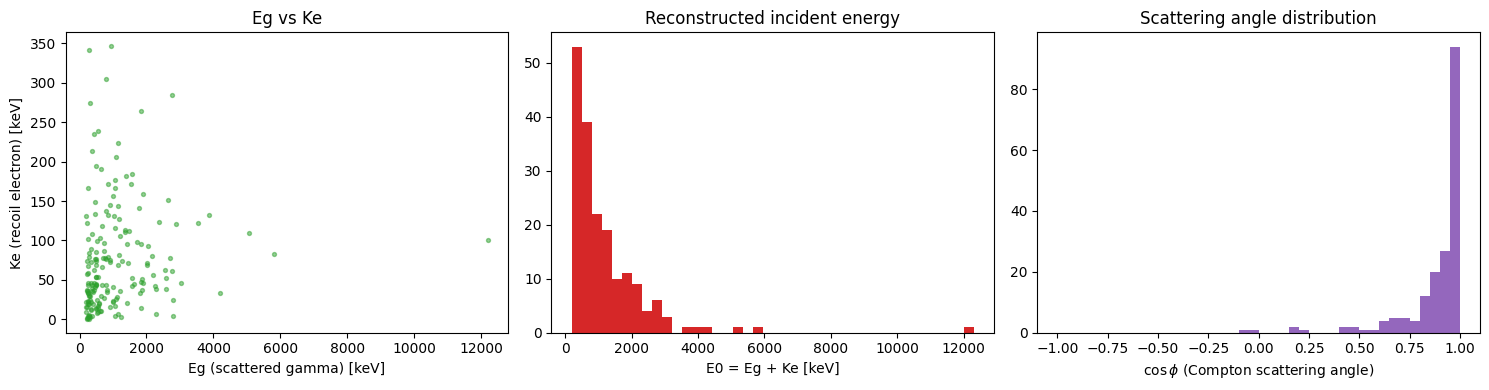

In [7]:
tree_rec = f.Get("Reconstruct/single_hit")
print("single_hit entries:", tree_rec.GetEntries())

Eg, Ke, E0, cos_phi = [], [], [], []
for i in range(tree_rec.GetEntries()):
    tree_rec.GetEntry(i)
    Eg.append(tree_rec.Eg)
    Ke.append(tree_rec.Ke)
    E0.append(tree_rec.E0)
    cos_phi.append(tree_rec.cos_phi)

Eg, Ke, E0, cos_phi = map(np.array, (Eg, Ke, E0, cos_phi))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(Eg, Ke, s=8, alpha=0.5, color="C2")
axes[0].set_xlabel("Eg (scattered gamma) [keV]")
axes[0].set_ylabel("Ke (recoil electron) [keV]")
axes[0].set_title("Eg vs Ke")

axes[1].hist(E0, bins=40, color="C3")
axes[1].set_xlabel("E0 = Eg + Ke [keV]")
axes[1].set_title("Reconstructed incident energy")

axes[2].hist(cos_phi, bins=40, range=(-1, 1), color="C4")
axes[2].set_xlabel(r"$\cos\phi$ (Compton scattering angle)")
axes[2].set_title("Scattering angle distribution")

fig.tight_layout()
plt.show()

## 次のステップ

- ここでは Per03_ETCC とは別キャンペーンの較正ファイルを流用しているため、`E0` / `Eg` / `Ke` の
  絶対値は参考値です。このデータセットに対応した較正ファイルを使えば正しいエネルギースケールになります
- `data_dir` を実フライトデータ(`mount_data/` 以下など)に差し替えれば、同じチェーンで解析できます
- モジュール構成・データ受け渡しの設計(インターフェース化、SMILE-3 シンチ対応)は
  Notion の「EricaNext 開発ドキュメント」を参照してください